# **Step4b -> "Reducción de dimensiones"**

##wd

In [73]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [74]:
!pwd

/content/drive/My Drive/raw_data


In [75]:
working_dir = "/content/drive/MyDrive/raw_data"
%cd $working_dir

/content/drive/MyDrive/raw_data


In [76]:
!pwd

/content/drive/MyDrive/raw_data


In [77]:
import pandas as pd

## Archivo de datos: **datos_censo.csv**


In [78]:
datos = pd.read_csv("datos_post_Step4a.csv", sep="|")
print(datos.shape)
datos.head()

(32560, 25)


,id,age,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,...,age_scaled,bin_age,qbin_age,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
0,1,39.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,40.0,...,0.301370,"(38.9, 46.2]","(34.0, 41.0]",False,False,False,False,False,True,False
1,2,50.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,13.0,...,0.452055,"(46.2, 53.5]","(41.0, 50.0]",False,False,False,False,True,False,False
2,3,38.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,40.0,...,0.287671,"(31.6, 38.9]","(34.0, 41.0]",False,False,True,False,False,False,False
3,4,53.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40.0,...,0.493151,"(46.2, 53.5]","(50.0, 90.0]",False,False,True,False,False,False,False
4,5,28.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40.0,...,0.150685,"(24.3, 31.6]","(26.0, 34.0]",False,False,True,False,False,False,False


In [79]:
# Omitimos duplicados
print(datos.shape)
datos.drop_duplicates(inplace=True)
print(datos.shape)

(32560, 25)
(32560, 25)


In [80]:
datos.dtypes

,0
id,int64
age,float64
education,object
education_num,float64
marital_status,object
occupation,object
relationship,object
race,object
gender,object
hours_per_week,float64


In [81]:
datos[['id', 'education', 'marital_status',	'occupation',
       'relationship',	'race',	'gender', 'native_country',	'greater_than_50k']] = datos[['id', 'education', 'marital_status',	'occupation',
                                                                                         'relationship',	'race',	'gender', 'native_country',	'greater_than_50k']].astype('string')
datos.dtypes

,0
id,string[python]
age,float64
education,string[python]
education_num,float64
marital_status,string[python]
occupation,string[python]
relationship,string[python]
race,string[python]
gender,string[python]
hours_per_week,float64


In [82]:
datos[['id',	'education', 'marital_status',	'occupation',
       'relationship',	'race',	'gender', 'native_country',	'greater_than_50k',
       'bin_age', 'qbin_age']] = datos[['id',	'education', 'marital_status',	'occupation',
                                        'relationship',	'race',	'gender', 'native_country',	'greater_than_50k', 'bin_age', 'qbin_age' ]].astype('string')
datos.dtypes

,0
id,string[python]
age,float64
education,string[python]
education_num,float64
marital_status,string[python]
occupation,string[python]
relationship,string[python]
race,string[python]
gender,string[python]
hours_per_week,float64


## Analizamos la correlación entre Variables Numéricas

In [83]:
datos.columns

Index(['id', 'age', 'education', 'education_num', 'marital_status',
       'occupation', 'relationship', 'race', 'gender', 'hours_per_week',
       'native_country', 'greater_than_50k', 'age_standarized_v1',
       'age_standarized_v2', 'age_standarized_v3', 'age_scaled', 'bin_age',
       'qbin_age', ' Local-gov', ' Never-worked', ' Private', ' Self-emp-inc',
       ' Self-emp-not-inc', ' State-gov', ' Without-pay'],
      dtype='object')

In [84]:
# Convertimos de True/False a 0/1
datos[" Local-gov"] = datos[" Local-gov"].astype(int)
datos[" Never-worked"] = datos[" Never-worked"].astype(int)
datos[" Private"] = datos[" Private"].astype(int)
datos[" Self-emp-inc"] = datos[" Self-emp-inc"].astype(int)
datos[" Self-emp-not-inc"] = datos[" Self-emp-not-inc"].astype(int)
datos[" State-gov"] = datos[" State-gov"].astype(int)
datos[" Without-pay"] = datos[" Without-pay"].astype(int)

In [85]:
numerical = datos.select_dtypes(exclude=['string', 'object']).columns.values
numerical

array(['age', 'education_num', 'hours_per_week', 'age_standarized_v1',
       'age_standarized_v2', 'age_standarized_v3', 'age_scaled',
       ' Local-gov', ' Never-worked', ' Private', ' Self-emp-inc',
       ' Self-emp-not-inc', ' State-gov', ' Without-pay'], dtype=object)

In [86]:
categorical = datos.select_dtypes(include=['string', 'object']).columns.values
categorical

array(['id', 'education', 'marital_status', 'occupation', 'relationship',
       'race', 'gender', 'native_country', 'greater_than_50k', 'bin_age',
       'qbin_age'], dtype=object)

<Axes: >

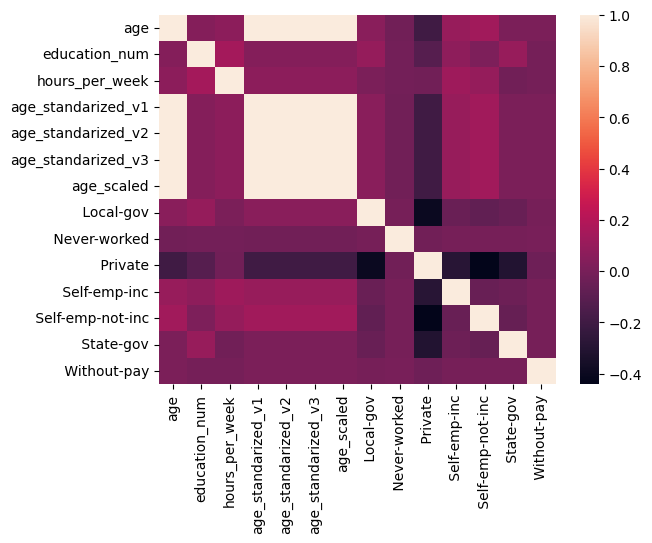

In [87]:
import seaborn as sns
sns.heatmap( datos[numerical].corr() )

<Axes: >

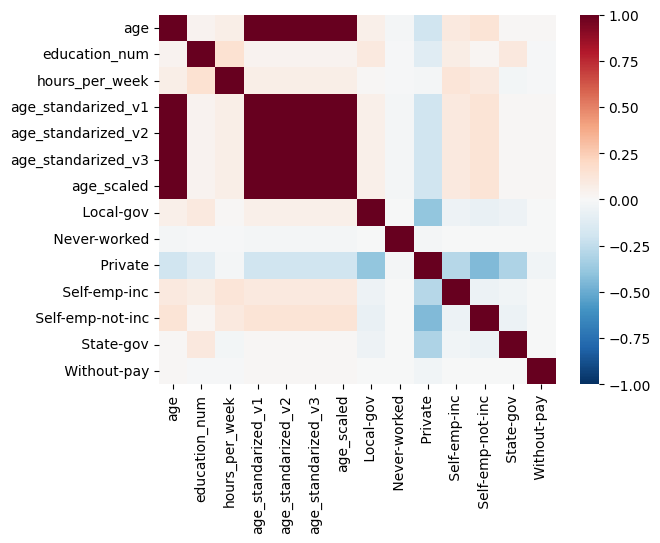

In [88]:
sns.heatmap( datos[numerical].corr(), vmin=-1, vmax=1, center=0, cmap='RdBu_r')

In [89]:
datos[numerical].head(5)

,age,education_num,hours_per_week,age_standarized_v1,age_standarized_v2,age_standarized_v3,age_scaled,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
0,39.0,13.0,40.0,0.028995,0.028996,0.105263,0.301370,0,0,0,0,0,1,0
1,50.0,13.0,13.0,0.841715,0.841728,0.684211,0.452055,0,0,0,0,1,0,0
2,38.0,9.0,40.0,-0.044888,-0.044889,0.052632,0.287671,0,0,1,0,0,0,0
3,53.0,7.0,40.0,1.063366,1.063382,0.842105,0.493151,0,0,1,0,0,0,0
4,28.0,13.0,40.0,-0.783725,-0.783737,-0.473684,0.150685,0,0,1,0,0,0,0


In [90]:

#import matplotlib.pyplot as plt
#import seaborn as sns

#sns.pairplot(datos, kind="scatter", hue="greater_than_50k", palette="Set2")


In [91]:
datos.drop(['age_standarized_v1', 'age_standarized_v2', 'age_standarized_v3', 'age_scaled'], axis=1, inplace=True)

In [92]:
#sns.pairplot(datos, kind="scatter", hue="greater_than_50k", palette="Set2")

## Preparación de datos

In [93]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [94]:
numerical = datos.select_dtypes(exclude=['string', 'object']).columns.values
numerical

array(['age', 'education_num', 'hours_per_week', ' Local-gov',
       ' Never-worked', ' Private', ' Self-emp-inc', ' Self-emp-not-inc',
       ' State-gov', ' Without-pay'], dtype=object)

In [95]:
datos[numerical]

,age,education_num,hours_per_week,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
0,39.0,13.0,40.0,0,0,0,0,0,1,0
1,50.0,13.0,13.0,0,0,0,0,1,0,0
2,38.0,9.0,40.0,0,0,1,0,0,0,0
3,53.0,7.0,40.0,0,0,1,0,0,0,0
4,28.0,13.0,40.0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
32555,27.0,12.0,38.0,0,0,1,0,0,0,0
32556,40.0,9.0,40.0,0,0,1,0,0,0,0
32557,58.0,9.0,40.0,0,0,1,0,0,0,0
32558,22.0,9.0,20.0,0,0,1,0,0,0,0


In [96]:
print(datos[numerical].describe())

#Estandarizamos las variables
X = (datos[numerical] -
     np.mean(datos[numerical], axis=0)) / np.std(datos[numerical], axis=0)

print(X.describe())

#Otra opción para estandarizar
#from sklearn.preprocessing import scale
#X = scale( datos[numerical] )
#print(pd.DataFrame(X).describe())


                age  education_num  hours_per_week     Local-gov  \
count  32560.000000   32560.000000    32560.000000  32560.000000   
mean      38.607555      10.092027       40.451032      0.064281   
std       13.534799       2.558426       12.310745      0.245257   
min       17.000000       1.000000        1.000000      0.000000   
25%       28.000000       9.000000       40.000000      0.000000   
50%       37.000000      10.000000       40.000000      0.000000   
75%       47.000000      12.000000       45.000000      0.000000   
max       90.000000      16.000000       99.000000      1.000000   

        Never-worked       Private   Self-emp-inc   Self-emp-not-inc  \
count   32560.000000  32560.000000   32560.000000       32560.000000   
mean        0.000215      0.697021       0.034275           0.078041   
std         0.014661      0.459553       0.181938           0.268239   
min         0.000000      0.000000       0.000000           0.000000   
25%         0.000000      0

In [97]:
X.shape

(32560, 10)

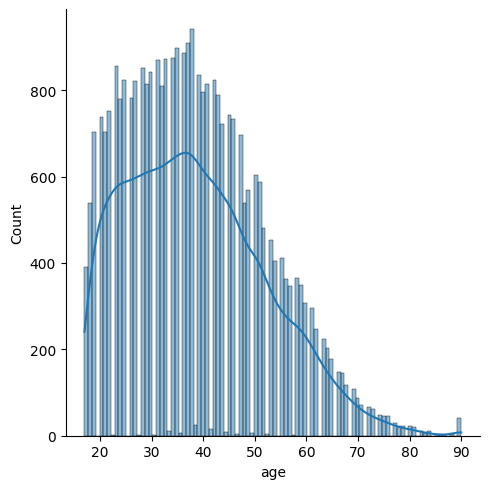

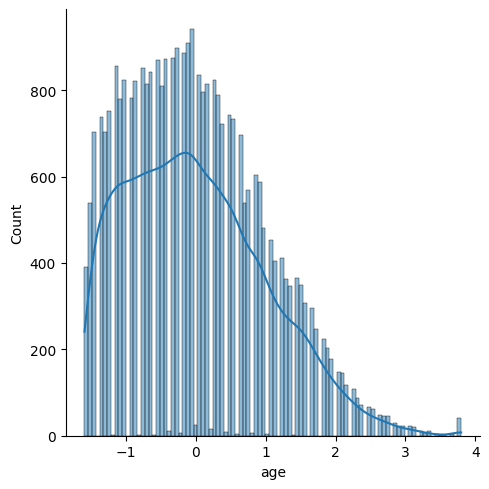

In [98]:
import seaborn as sns
sns.displot(datos, x='age', kde=True, bins=100)
sns.displot(X, x='age', kde=True, bins=100)         #sns.displot(pd.DataFrame(X), x=0, kde=True, bins=100)

## Reducimos la dimensionalidad con PCA

In [99]:
!pip install factor_analyzer

In [100]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

# H0: Todas las correlaciones son cero  -> No se observa correlación entre las 3 variables
# Ha: Al menos una de las correlaciones es diferente de cero

chi_square_value, p_value = calculate_bartlett_sphericity(datos[numerical])
p_value

# Rechazar H0, si p-value <= 0.05     → Sí se recomienda aplicar PCA
# No rechazar H0, si p-value > 0.05   → No se recomienda aplicar PCA

np.float64(0.0)

In [101]:
# PCA
from sklearn.decomposition import PCA
pca = PCA().fit(X)
pca_loadings = pca.components_    # ndarray of shape (n_components, n_features)
pca_loadings

array([[-0.31404073, -0.24522759, -0.17390757, -0.31648521,  0.0022757 ,
         0.66549479, -0.27078734, -0.37891943, -0.22515737, -0.01857591],
       [ 0.17813498,  0.2133754 ,  0.62288296, -0.35120064, -0.1159013 ,
         0.23597205,  0.43990447,  0.04758901, -0.37470479, -0.07818917],
       [ 0.23978557, -0.51361704, -0.13180115, -0.27773537,  0.04579013,
        -0.0581699 , -0.182964  ,  0.65146119, -0.33749685,  0.08324559],
       [ 0.07431483, -0.07629377,  0.01076893,  0.70147575, -0.01265923,
         0.01561207, -0.02565444, -0.14992816, -0.68739276,  0.02056628],
       [ 0.10442477, -0.22715147, -0.17022503, -0.09575601,  0.42088086,
        -0.06276902,  0.5055241 , -0.27275358, -0.01379669,  0.62300222],
       [-0.13553512, -0.01614074,  0.05003191,  0.0023406 ,  0.80967435,
        -0.03413827,  0.07306656,  0.05112867, -0.05594054, -0.55771037],
       [-0.20361656,  0.3833811 ,  0.34397896,  0.03822046,  0.34847184,
         0.08631439, -0.47795319,  0.22357082

Nota: Para un conjunto de datos de **n** observaciones y **p** variables, obtendremos: **min(n-1, p)** componentes principales


In [102]:
X.shape  # ->>> min(22740, 3) componentes principales

(32560, 10)

In [103]:
# Cargas por PC
pd.DataFrame(pca_loadings,  # ndarray of shape (n_components, n_features)
             columns= datos[numerical].columns,
             index = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10'])

,age,education_num,hours_per_week,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
PC1,-0.314041,-0.245228,-0.173908,-0.316485,0.002276,0.665495,-0.270787,-0.378919,-0.225157,-0.018576
PC2,0.178135,0.213375,0.622883,-0.351201,-0.115901,0.235972,0.439904,0.047589,-0.374705,-0.078189
PC3,0.239786,-0.513617,-0.131801,-0.277735,0.045790,-0.058170,-0.182964,0.651461,-0.337497,0.083246
PC4,0.074315,-0.076294,0.010769,0.701476,-0.012659,0.015612,-0.025654,-0.149928,-0.687393,0.020566
PC5,0.104425,-0.227151,-0.170225,-0.095756,0.420881,-0.062769,0.505524,-0.272754,-0.013797,0.623002
PC6,-0.135535,-0.016141,0.050032,0.002341,0.809674,-0.034138,0.073067,0.051129,-0.055941,-0.557710
PC7,-0.203617,0.383381,0.343979,0.038220,0.348472,0.086314,-0.477953,0.223571,-0.039641,0.531883
PC8,0.856955,0.107472,-0.020076,-0.006882,0.171953,0.215782,-0.312986,-0.240274,0.137599,-0.053601
PC9,0.033632,0.643452,-0.639171,-0.187383,0.007508,0.037854,0.127376,0.165677,-0.309586,-0.013410
PC10,0.019751,-0.017069,-0.074440,0.401864,0.023121,0.661254,0.309042,0.441704,0.320655,0.032612


In [104]:
# Scores o puntajes de las Componetes Principales
pca_scores = pca.transform(X)
pca_scores

array([[-2.15129224, -1.9732948 , -2.22476516, ...,  0.62499765,
        -0.84389606,  0.26151282],
       [-2.28687389, -1.1019745 ,  2.41295685, ..., -0.23357449,
         2.78536377,  0.44854223],
       [ 0.85434272,  0.10868447,  0.15904642, ...,  0.15988493,
        -0.18762171,  0.08667786],
       ...,
       [ 0.39028626,  0.37191367,  0.51337639, ...,  1.42620268,
        -0.13792363,  0.11586342],
       [ 1.50812196, -1.11384826,  0.08970949, ..., -0.82055373,
         0.81103149,  0.18426607],
       [-2.40702595,  2.19737489, -0.47199651, ..., -1.1435642 ,
         0.46491182,  0.36681673]])

In [105]:
datos[numerical]

,age,education_num,hours_per_week,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
0,39.0,13.0,40.0,0,0,0,0,0,1,0
1,50.0,13.0,13.0,0,0,0,0,1,0,0
2,38.0,9.0,40.0,0,0,1,0,0,0,0
3,53.0,7.0,40.0,0,0,1,0,0,0,0
4,28.0,13.0,40.0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
32555,27.0,12.0,38.0,0,0,1,0,0,0,0
32556,40.0,9.0,40.0,0,0,1,0,0,0,0
32557,58.0,9.0,40.0,0,0,1,0,0,0,0
32558,22.0,9.0,20.0,0,0,1,0,0,0,0


In [106]:
datos_pca = pd.DataFrame(pca_scores, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10'], index=datos[numerical].index)
datos_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,-2.151292,-1.973295,-2.224765,-3.617747,-0.231306,-0.276425,0.090635,0.624998,-0.843896,0.261513
1,-2.286874,-1.101975,2.412957,-0.626381,-0.719416,-0.019766,0.206831,-0.233574,2.785364,0.448542
2,0.854343,0.108684,0.159046,0.043549,0.050058,-0.029528,-0.103283,0.159885,-0.187622,0.086678
3,0.698005,0.139302,0.826310,0.185552,0.343362,-0.167120,-0.628651,1.025608,-0.653362,0.121910
4,0.702961,0.310679,-0.821151,-0.130643,-0.382244,0.045376,0.646569,-0.305243,0.793557,0.045399
...,...,...,...,...,...,...,...,...,...,...
32555,0.850270,0.112920,-0.616697,-0.108062,-0.273518,0.053570,0.455877,-0.407305,0.643406,0.062705
32556,0.807937,0.135007,0.194479,0.054530,0.065488,-0.049556,-0.133371,0.286517,-0.182652,0.089596
32557,0.390286,0.371914,0.513376,0.153363,0.204365,-0.229808,-0.404166,1.426203,-0.137924,0.115863
32558,1.508122,-1.113848,0.089709,-0.061798,0.203162,0.049413,-0.421412,-0.820554,0.811031,0.184266


In [107]:
explained_variance = pca.explained_variance_ # No me eprmite saber mucho la variabilidad

print('Varianza explicada por PC:')
print(explained_variance)
print(np.round(explained_variance, 1))

Varianza explicada por PC:
[1.80361359 1.17114848 1.13354176 1.05744815 1.0125     1.00354522
 0.97551319 0.87570733 0.78981566 0.17747376]
[1.8 1.2 1.1 1.1 1.  1.  1.  0.9 0.8 0.2]


In [108]:
PVE = pca.explained_variance_ratio_ # Antes: 100%; Despues: 70% + 25%
PVE_acum = np.cumsum(pca.explained_variance_ratio_)

print('Proporción de varianza explicada por PC:')
print(PVE)
print('Proporción acumulada de varianza explicada por PC:')
print(PVE_acum) # Si me quedo con las 6 primeras componentes, solo tenemos el 71% de los datos

Proporción de varianza explicada por PC:
[0.18035582 0.11711125 0.11335069 0.10574157 0.10124689 0.10035144
 0.09754832 0.08756804 0.07897914 0.01774683]
Proporción acumulada de varianza explicada por PC:
[0.18035582 0.29746707 0.41081776 0.51655933 0.61780622 0.71815766
 0.81570598 0.90327403 0.98225317 1.        ]


Text(0.5, 1.0, 'Gráfico de sedimentación')

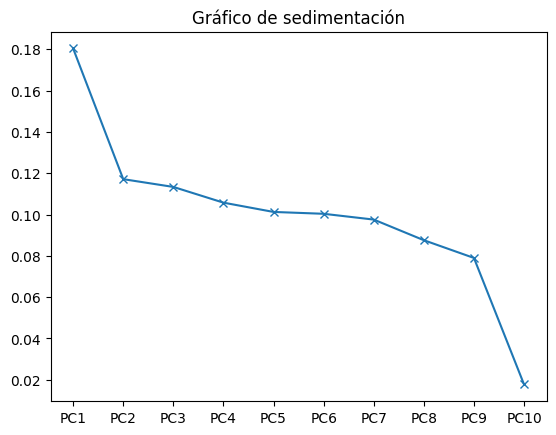

In [109]:
plt.plot(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10'], PVE , marker='x' )
plt.title('Gráfico de sedimentación')

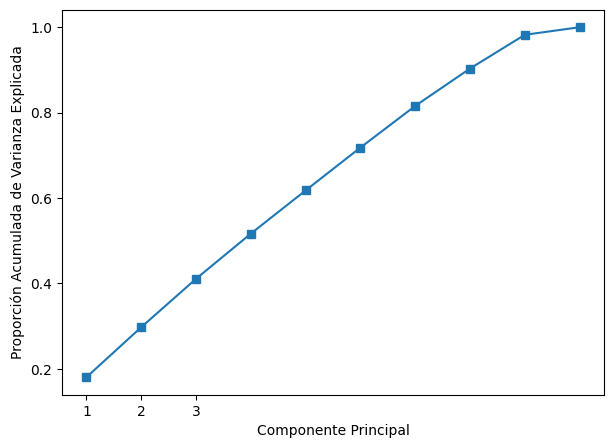

In [110]:
plt.figure(figsize=(7,5))
plt.plot([1,2,3,4,5,6,7,8,9,10], PVE_acum, '-s')
plt.ylabel('Proporción Acumulada de Varianza Explicada')
plt.xlabel('Componente Principal')
plt.xticks([1,2,3])
plt.show()

In [111]:
import plotly.express as px

px.area(
    x=range(1, PVE_acum.shape[0] + 1),
    y=PVE_acum,
    labels={"x": "# Components", "y": "Explained Variance"}
)

In [112]:
datos_pca_plot = datos_pca.copy()
datos_pca_plot['greater_than_50k'] = datos['greater_than_50k'] # Al momento de agergar una target se vera una separacion de poblaciones

In [113]:
import plotly.express as px

fig = px.scatter(datos_pca_plot, x='PC1', y='PC2', color='greater_than_50k')
fig.show()

In [114]:
import plotly.express as px
from sklearn.decomposition import PCA

fig = px.scatter_3d( datos_pca_plot, x='PC1', y='PC2', z='PC3', color='greater_than_50k'
)
fig.show()

## Reducimos la dimensionalidad con EFA

In [115]:
#!pip install factor_analyzer

In [116]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

# H0: La matriz de correlaciones es una matriz identidad
#     No existe correlación entre las variables
#
# Ha: La matriz de correlaciones NO es una matriz identidad
#     Existe correlación entre las variables

chi_square_value, p_value = calculate_bartlett_sphericity(
    datos[numerical]
)

print("Chi-cuadrado:", chi_square_value)
print("p-value:", p_value)

Chi-cuadrado: 38341.97899399574
p-value: 0.0


In [117]:
#Prueba KMO

#Esta prueba es especialmente importante para AFE

from factor_analyzer.factor_analyzer import calculate_kmo

kmo_all, kmo_model = calculate_kmo(datos[numerical])

print("KMO:", kmo_model) # Es malo que se va a perder el 23% de los datos

KMO: 0.23397054595139538


/usr/local/lib/python3.13/dist-packages/factor_analyzer/utils.py:244: UserWarning:

The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.



In [118]:
#KMO de cada variable:

kmo_variables = pd.DataFrame({ 'Variable': datos[numerical].columns,'KMO': kmo_all })
kmo_variables # Contribucion de cada una de las variables para el 100% de mi informacion

,Variable,KMO
0,age,0.810993
1,education_num,0.631077
2,hours_per_week,0.370576
3,Local-gov,0.172560
4,Never-worked,0.179283
5,Private,0.299974
6,Self-emp-inc,0.154859
7,Self-emp-not-inc,0.197182
8,State-gov,0.144353
9,Without-pay,0.118348


In [119]:
#Determinar el número de factores: Primero obtenemos los valores propios

from factor_analyzer import FactorAnalyzer

fa = FactorAnalyzer(rotation=None)
fa.fit(X)
eigenvalues, vectors = fa.get_eigenvalues()

print("Valores propios:")
print(eigenvalues)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



Valores propios:
[1.80355819 1.17111251 1.13350694 1.05741567 1.01246891 1.0035144
 0.97548323 0.87568044 0.7897914  0.17746831]


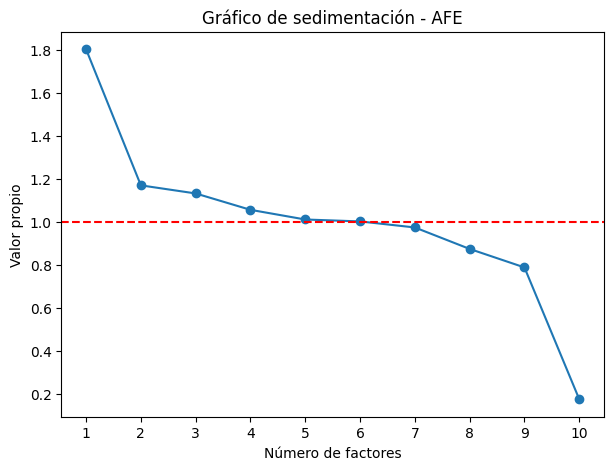

In [120]:
#Gráfico de sedimentación

plt.figure(figsize=(7,5))

plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o' )

plt.axhline(
    y=1, # Si consideramos autovalores, consideramos umbral=1
    color='red',
    linestyle='--'
)

plt.xlabel('Número de factores')
plt.ylabel('Valor propio')
plt.title('Gráfico de sedimentación - AFE')

plt.xticks(range(1, len(eigenvalues) + 1))

plt.show()

In [121]:
#Aplicamos el AFE
#Supongamos que el análisis anterior indica que utilizarás 2 factores.

fa = FactorAnalyzer(
    n_factors=2,
    rotation='varimax',
    method='minres'
)

fa.fit(X)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



FactorAnalyzer(n_factors=2, rotation='varimax', rotation_kwargs={})

Aquí:

n_factors=2 → extraemos 2 factores.

rotation='varimax' → rotación para facilitar la interpretación.

method='minres' → método de extracción de factores.

Si tu análisis indica 1 o 3 factores, simplemente cambias:

In [122]:
# Cargas factoriales

factor_loadings = fa.loadings_ # Esto tmb tenemos en PCA; la misma idea de cargas

factor_loadings_df = pd.DataFrame(
    factor_loadings,
    columns=['Factor 1', 'Factor 2'],
    index=datos[numerical].columns
)

factor_loadings_df # Las cargas son contribuciones para cada uno de mis factores; Se tiene que elegir en valor absoluto en que factor se queda cada variable

,Factor 1,Factor 2
age,0.164967,0.135007
education_num,0.044218,0.165336
hours_per_week,0.087618,0.027836
Local-gov,0.035285,0.368112
Never-worked,-0.000156,0.010622
Private,-0.594024,-0.832757
Self-emp-inc,0.046320,0.239061
Self-emp-not-inc,0.983643,-0.210910
State-gov,0.028459,0.254893
Without-pay,0.004125,0.021208


In [123]:
#redondeadas:

factor_loadings_df.round(3)

,Factor 1,Factor 2
age,0.165,0.135
education_num,0.044,0.165
hours_per_week,0.088,0.028
Local-gov,0.035,0.368
Never-worked,-0.000,0.011
Private,-0.594,-0.833
Self-emp-inc,0.046,0.239
Self-emp-not-inc,0.984,-0.211
State-gov,0.028,0.255
Without-pay,0.004,0.021


In [124]:
#Scores o puntajes factoriales

factor_scores = fa.transform(X)

factor_scores

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



array([[ 0.13695803,  1.30684413],
       [ 3.4122544 , -0.9390423 ],
       [-0.39020109, -0.57686029],
       ...,
       [-0.38457519, -0.57144282],
       [-0.37403675, -0.76837339],
       [ 0.25855012,  1.12834461]])

In [125]:
datos_factores = pd.DataFrame(
    factor_scores,
    columns=['Factor 1', 'Factor 2'],
    index=datos[numerical].index
)

datos_factores


,Factor 1,Factor 2
0,0.136958,1.306844
1,3.412254,-0.939042
2,-0.390201,-0.576860
3,-0.384122,-0.629970
4,-0.396733,-0.465224
...,...,...
32555,-0.394018,-0.512799
32556,-0.389639,-0.576319
32557,-0.384575,-0.571443
32558,-0.374037,-0.768373


In [126]:
#Comunalidades

#Esta es una parte propia del análisis factorial que no tienes en PCA.

communalities = fa.get_communalities()

comunalidades_df = pd.DataFrame(
    communalities,
    index=datos[numerical].columns,
    columns=['Comunalidad']
)

comunalidades_df

#La comunalidad indica qué proporción de la varianza de cada variable queda explicada por los factores comunes.

,Comunalidad
age,0.045441
education_num,0.029291
hours_per_week,0.008452
Local-gov,0.136752
Never-worked,0.000113
Private,1.046349
Self-emp-inc,0.059296
Self-emp-not-inc,1.012036
State-gov,0.065780
Without-pay,0.000467


In [127]:
# Varianza explicada

variance = fa.get_factor_variance()

SS_loadings = variance[0]
proportion_variance = variance[1]
cumulative_variance = variance[2]

varianza_factores = pd.DataFrame({
    'Factor': ['Factor 1', 'Factor 2'],
    'SS Loadings': SS_loadings,
    'Proporción de varianza': proportion_variance,
    'Proporción acumulada': cumulative_variance
})

varianza_factores

,Factor,SS Loadings,Proporción de varianza,Proporción acumulada
0,Factor 1,1.361482,0.136148,0.136148
1,Factor 2,1.042495,0.104250,0.240398


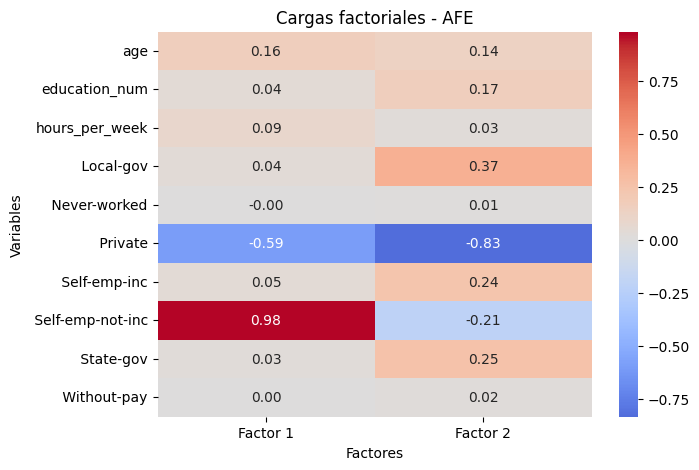

In [128]:
#Visualizar las cargas factoriales

plt.figure(figsize=(7,5))

sns.heatmap(
    factor_loadings_df,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Cargas factoriales - AFE')
plt.xlabel('Factores')
plt.ylabel('Variables')

plt.show()

In [129]:
# Gráfico de los factores

datos_factores_plot = datos_factores.copy()
datos_factores_plot['greater_than_50k'] = \
    datos['greater_than_50k']


import plotly.express as px

fig = px.scatter(
    datos_factores_plot,
    x='Factor 1',
    y='Factor 2',
    color='greater_than_50k'
)

fig.show()

## Guardamos los datos

In [130]:
print(datos_pca.shape)
datos_pca

(32560, 10)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,-2.151292,-1.973295,-2.224765,-3.617747,-0.231306,-0.276425,0.090635,0.624998,-0.843896,0.261513
1,-2.286874,-1.101975,2.412957,-0.626381,-0.719416,-0.019766,0.206831,-0.233574,2.785364,0.448542
2,0.854343,0.108684,0.159046,0.043549,0.050058,-0.029528,-0.103283,0.159885,-0.187622,0.086678
3,0.698005,0.139302,0.826310,0.185552,0.343362,-0.167120,-0.628651,1.025608,-0.653362,0.121910
4,0.702961,0.310679,-0.821151,-0.130643,-0.382244,0.045376,0.646569,-0.305243,0.793557,0.045399
...,...,...,...,...,...,...,...,...,...,...
32555,0.850270,0.112920,-0.616697,-0.108062,-0.273518,0.053570,0.455877,-0.407305,0.643406,0.062705
32556,0.807937,0.135007,0.194479,0.054530,0.065488,-0.049556,-0.133371,0.286517,-0.182652,0.089596
32557,0.390286,0.371914,0.513376,0.153363,0.204365,-0.229808,-0.404166,1.426203,-0.137924,0.115863
32558,1.508122,-1.113848,0.089709,-0.061798,0.203162,0.049413,-0.421412,-0.820554,0.811031,0.184266


In [131]:
print(datos.shape)
datos

(32560, 21)


,id,age,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,...,greater_than_50k,bin_age,qbin_age,Local-gov,Never-worked,Private,Self-emp-inc,Self-emp-not-inc,State-gov,Without-pay
0,1,39.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,40.0,...,0,"(38.9, 46.2]","(34.0, 41.0]",0,0,0,0,0,1,0
1,2,50.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,13.0,...,0,"(46.2, 53.5]","(41.0, 50.0]",0,0,0,0,1,0,0
2,3,38.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,40.0,...,0,"(31.6, 38.9]","(34.0, 41.0]",0,0,1,0,0,0,0
3,4,53.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40.0,...,0,"(46.2, 53.5]","(50.0, 90.0]",0,0,1,0,0,0,0
4,5,28.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40.0,...,0,"(24.3, 31.6]","(26.0, 34.0]",0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32555,32556,27.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,38.0,...,0,"(24.3, 31.6]","(26.0, 34.0]",0,0,1,0,0,0,0
32556,32557,40.0,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40.0,...,1,"(38.9, 46.2]","(34.0, 41.0]",0,0,1,0,0,0,0
32557,32558,58.0,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,40.0,...,0,"(53.5, 60.8]","(50.0, 90.0]",0,0,1,0,0,0,0
32558,32559,22.0,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,Male,20.0,...,0,"(16.927, 24.3]","(16.999, 26.0]",0,0,1,0,0,0,0


In [132]:
numerical

array(['age', 'education_num', 'hours_per_week', ' Local-gov',
       ' Never-worked', ' Private', ' Self-emp-inc', ' Self-emp-not-inc',
       ' State-gov', ' Without-pay'], dtype=object)

In [133]:
datos_reducPCA = pd.concat( [datos.drop(numerical, axis=1), datos_pca.drop(['PC3'], axis=1) ], axis=1) # Elimino los originales y los componentes nuevos que no quiero. Me quedo con los nuevos que sí quier
print(datos_reducPCA.shape)
datos_reducPCA.head(3)

(32560, 20)


,id,education,marital_status,occupation,relationship,race,gender,native_country,greater_than_50k,bin_age,qbin_age,PC1,PC2,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,1,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,0,"(38.9, 46.2]","(34.0, 41.0]",-2.151292,-1.973295,-3.617747,-0.231306,-0.276425,0.090635,0.624998,-0.843896,0.261513
1,2,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,0,"(46.2, 53.5]","(41.0, 50.0]",-2.286874,-1.101975,-0.626381,-0.719416,-0.019766,0.206831,-0.233574,2.785364,0.448542
2,3,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,0,"(31.6, 38.9]","(34.0, 41.0]",0.854343,0.108684,0.043549,0.050058,-0.029528,-0.103283,0.159885,-0.187622,0.086678


In [134]:
datos_reducEFA = pd.concat( [datos.drop(numerical, axis=1), datos_factores ], axis=1 )
print(datos_reducEFA.shape)
datos_reducEFA.head(3)

(32560, 13)


,id,education,marital_status,occupation,relationship,race,gender,native_country,greater_than_50k,bin_age,qbin_age,Factor 1,Factor 2
0,1,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,0,"(38.9, 46.2]","(34.0, 41.0]",0.136958,1.306844
1,2,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,0,"(46.2, 53.5]","(41.0, 50.0]",3.412254,-0.939042
2,3,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,0,"(31.6, 38.9]","(34.0, 41.0]",-0.390201,-0.576860


In [135]:
#datos_reducPCA.to_csv('datos_post_Step4b.csv', index=False, sep='|', encoding='latin-1')
#datos_reducEFA.to_csv('datos_post_Step4c.csv', index=False, sep='|', encoding='latin-1')